In [16]:
!pip install pca



[notice] A new release of pip is available: 24.3.1 -> 25.0
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import pandas as pd
import numpy as np
import time
import datetime
import os
import json
import requests
import random
from pca import pca

In [23]:
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from sklearn.metrics.pairwise import pairwise_distances
from mpl_toolkits.mplot3d import Axes3D

from collections import Counter

In [3]:
api_key = '***REMOVED***'
dataPath = "./download"
db = []

In [4]:
def convert_timestamp_to_datetime(timestamp):
    return datetime.datetime.fromtimestamp(int(timestamp)).strftime('%Y-%m-%d %H:%M:%S')

In [5]:
# Get up-to-date hero stats 
def get_hero_stats():
    url = f"https://api.opendota.com/api/heroStats?api_key={api_key}"
    response = requests.get(url)
    data = response.json()
    pd.DataFrame(data).to_csv("hero_stats.csv", index=False, sep=",")
    with open("hero_stats.json", "w") as outfile:
        json.dump(data, outfile)

In [6]:
get_hero_stats()

In [7]:
# Download the data from OpenDota   
def get_match_by_id(match_id):
    m_id = str(match_id)
    url = f"https://api.opendota.com/api/matches/{m_id}?api_key={api_key}"
    response = requests.get(url)
    if response.status_code == 200:
        print("Get: ", m_id)
        data = response.json()
        file = open("./download/"+ m_id + ".json" , "w")
        json.dump(data, file)
        file.close()
match_id = 7770000000
for i in range(100000):
    get_match_by_id(random.randrange(0,400000000,3)+match_id)
    time.sleep(2)

Get:  7859780202
Get:  8027601150
Get:  8096186403
Get:  7859907321
Get:  8104307001
Get:  7978604160
Get:  7921155153
Get:  7910520657
Get:  7948544544
Get:  7981837077
Get:  7873839579
Get:  7972732653
Get:  8048039688
Get:  7988781873
Get:  8102886783
Get:  8139057615
Get:  7818622083
Get:  8013945387
Get:  7937183646
Get:  8029477983
Get:  7849245450
Get:  7964633154
Get:  8096685966
Get:  7955661456
Get:  7821436989
Get:  8065218561
Get:  7917419151
Get:  7912798338
Get:  7980594087
Get:  7908626820
Get:  7926376254
Get:  7896680517
Get:  8128237722
Get:  8015417316
Get:  7898069469
Get:  7942685559
Get:  8099221542
Get:  8082364812
Get:  7884995034
Get:  7821478026
Get:  8134510497
Get:  7879480617
Get:  7916868432
Get:  7903920213
Get:  8022942423
Get:  8110073091
Get:  7810927026
Get:  7975591233
Get:  7888655667
Get:  8133337794
Get:  7806016071
Get:  7976442372
Get:  7868394399
Get:  8056205613
Get:  8126314182
Get:  8077692096
Get:  7776552774
Get:  8015659734
Get:  78909805

KeyboardInterrupt: 

In [11]:
def process_dota_matches(data_path):
    db = []  # Initialize the database list
    
    for filename in os.listdir(data_path):
        file_path = os.path.join(data_path, filename)
        
        # Check if it's a JSON file
        if os.path.isfile(file_path) and filename.endswith('.json'):
            print(f"Processing JSON file: {filename}")
            
            # Safely load JSON file
            try:
                with open(file_path, 'r') as f:
                    data = json.load(f)
            except json.JSONDecodeError as e:
                print(f"Error reading {filename}: {e}")
                continue
                
            # Skip files with errors
            if "error" in data:
                print(f"Skipping {filename}: Contains error flag")
                continue
                
            # Apply filters
            if (int(data.get("duration", 0)) < 600 or 
                int(data.get("human_players", 0)) != 10 or
                int(data.get("lobby_type", 0)) != 7):
                print(f"Skipping {filename}: Does not meet criteria")
                continue
            
            # Process player data
            try:
                player_data = pd.DataFrame(data["players"])
                
                # Columns to drop
                columns_to_drop = [
                    'player_slot', 'team_number', 'team_slot', 
                    'item_0', 'item_1', 'item_2', 'item_3', 'item_4', 'item_5',
                    'backpack_0', 'backpack_1', 'backpack_2', 'item_neutral', 'leaver_status',
                    'radiant_win', 'start_time', 'duration', 'cluster', 'lobby_type', 'game_mode',
                    'is_contributor', 'patch', 'win', 'lose', 'abandons'
                ]
                
                # Drop only columns that exist
                columns_to_drop = [col for col in columns_to_drop if col in player_data.columns]
                player_data_dropped = player_data.drop(columns=columns_to_drop)
                
                # Process each player
                for i, player in player_data_dropped.iterrows():
                    final_player_data = {
                        'match_id': data['match_id'],
                        'is_radiant': player['isRadiant'],
                        'player_slot': i,
                        'hero_id': player['hero_id'],
                        'kills': player['kills'],
                        'deaths': player['deaths'],
                        'assists': player['assists'],
                        'last_hits': player['last_hits'],
                        'denies': player['denies'],
                        'gold_per_min': player['gold_per_min'],
                        'xp_per_min': player['xp_per_min'],
                        'level': player['level'],
                        'net_worth': player['net_worth'],
                        'hero_damage': player['hero_damage'],
                        'tower_damage': player['tower_damage'],
                        'hero_healing': player['hero_healing'],
                        'gold_spent': player['gold_spent'],
                        'total_gold': player['total_gold'],
                        'total_xp': player['total_xp']
                    }
                    
                    # Append the player data to db list
                    db.append(final_player_data)  # Fixed variable name
                    
            except KeyError as e:
                print(f"Error processing {filename}: Missing key {e}")
                continue
            except Exception as e:
                print(f"Unexpected error processing {filename}: {e}")
                continue
    
    # Create final DataFrame
    db_df = pd.DataFrame(db)
    return db_df

In [12]:
db_df = process_dota_matches(dataPath)



Processing JSON file: 7770049218.json
Skipping 7770049218.json: Does not meet criteria
Processing JSON file: 7770513501.json
Skipping 7770513501.json: Does not meet criteria
Processing JSON file: 7770522972.json
Processing JSON file: 7770850503.json
Skipping 7770850503.json: Does not meet criteria
Processing JSON file: 7771012332.json
Skipping 7771012332.json: Does not meet criteria
Processing JSON file: 7772125806.json
Processing JSON file: 7772169285.json
Processing JSON file: 7772823447.json
Processing JSON file: 7773389235.json
Skipping 7773389235.json: Does not meet criteria
Processing JSON file: 7773906780.json
Skipping 7773906780.json: Does not meet criteria
Processing JSON file: 7774240704.json
Processing JSON file: 7775131119.json
Processing JSON file: 7775276787.json
Skipping 7775276787.json: Does not meet criteria
Processing JSON file: 7775363619.json
Processing JSON file: 7775433738.json
Skipping 7775433738.json: Does not meet criteria
Processing JSON file: 7775503314.json


In [13]:
print(db_df.head())

     match_id  is_radiant  player_slot  hero_id  kills  deaths  assists  \
0  7770522972        True            0       14     18       6       33   
1  7770522972        True            1       68     13       6       24   
2  7770522972        True            2       76     12       4       18   
3  7770522972        True            3       18     10       6       11   
4  7770522972        True            4       64     10       6       25   

   last_hits  denies  gold_per_min  xp_per_min  level  net_worth  hero_damage  \
0        158       7           580         987     26      22779        34594   
1        147       0           512         804     25      20225        25678   
2        218       7           570         940     26      23106        33662   
3        324       8           636        1003     27      24192        25145   
4         73       1           435         832     25      16516        28759   

   tower_damage  hero_healing  gold_spent  total_gold  total_x

In [14]:
db_df.to_csv('filename.csv', index=False)

In [25]:
# Standardize the data
scaler = StandardScaler()
scaler_db = scaler.fit_transform(db_df.drop(columns=['match_id', 'is_radiant', 'player_slot']))

The optimal number of PCA's is: 12


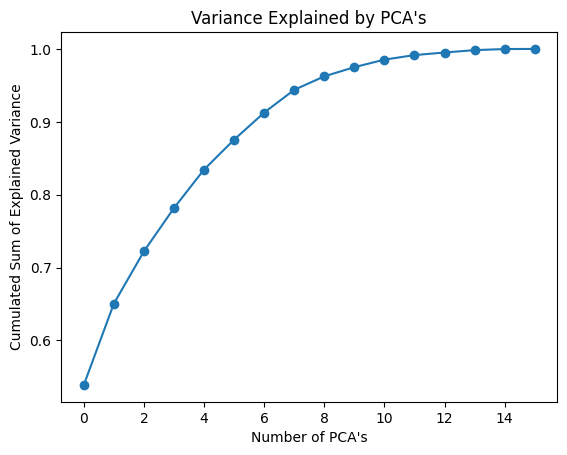

In [27]:
# Find the optimal number of PCA 
model = PCA(n_components=scaler_db.shape[1])
model.fit(scaler_db)
ratios = model.explained_variance_ratio_

# Plot the explained variance ratios
x = np.arange(scaler_db.shape[1])
plt.plot(x, np.cumsum(ratios), '-o')
plt.xlabel("Number of PCA's")
plt.ylabel("Cumulated Sum of Explained Variance")
plt.title("Variance Explained by PCA's")

# Find the optimal number of PCA's
for i in range(np.cumsum(ratios).shape[0]):
  if np.cumsum(ratios)[i] >= 0.99:
    num_pca = i + 1
    print(f"The optimal number of PCA's is: {num_pca}")
    break
  else:
    continue